# Dataset C: ESPN Player Contracts via hoopR (2015-16 to 2025-26)

This notebook builds the **contract-term** features:

| Feature | Column | Status |
|---|---|---|
| Number of years left on the contract | `years_remaining` | built |
| Expiring-contract flag | `expiring_contract` | built, **used as a filter, not a model feature**: `999_combining` keeps only `expiring_contract == False` (players under contract for the next season) |
| Minimum-salary contract flag | `min_salary_contract` | built (after correcting ESPN's flag) |

Option type and trade kicker were considered but are **not used**. ESPN reports placeholder values for both (section 4a).

*Run order: `01` → `02` → `03` → `999`. This notebook reads `cap_thresholds_clean.csv` from notebook 01.*

- **Dataset name:** ESPN NBA player contracts, as exposed by hoopR's [`espn_nba_player_contract()`](https://hoopr.sportsdataverse.org/reference/espn_nba_player_contracts.html)
- **How we access it:** hoopR is an R package that wraps ESPN's public API. Our project is in Python, so we call **the same ESPN endpoint hoopR uses**, `sports.core.api.espn.com/v2/sports/basketball/leagues/nba/athletes/{athlete_id}/contracts/{season}`, which returns the same fields as hoopR's output.
- **Which players:** ESPN's contract endpoint needs an ESPN athlete id. ESPN's season athlete list only returns *current* players, so for each season we take everyone on ESPN's regular-season stats leaderboard for that season (every player who appeared in a game). That also gives each player's **team at the end of that season**.
- **Saved as:** `data-files/00-raw/espn_athletes_by_season_raw.json`, `espn_player_contracts_raw.json`, `espn_teams_raw.json` (downloaded by `download_espn_contracts()` in `nba_cleaning_utils.py` if missing; takes about 1 minute)

## Important variables (ESPN field → hoopR column)

| ESPN field | hoopR column | Units | Meaning |
|---|---|---|---|
| `yearsRemaining` | `years_remaining` | years | Years left on the contract, **counting the current season** (verified below). |
| `salary` | `salary` | USD | Cap salary for that season |
| `minimumSalaryException` | `minimum_salary_exception` | true/false | Signed with the minimum-salary exception, the rule that lets a team **already over the cap** sign a player for the league minimum |
| `optionType` | `option_type` | code | Player/team option code |
| `tradeKicker.active`, `.percentage` | `trade_kicker_active`, `trade_kicker_percentage` | true/false, % | Bonus paid to the player if traded |
| `team.$ref` | `team_id` | id | ESPN team id attached to the contract |

**Season convention:** ESPN's contract `season` is the **end year** (2026 = 2025-26), the same as our other notebooks. We confirm this below with LeBron James's contract history.

## Setup

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nba_cleaning_utils import (RAW, PROCESSED, FIRST_SEASON, LAST_SEASON,
                                ESPN_TO_NBA_ABBREV, normalize_name, download_espn_contracts)

## 1. Download (skipped if the raw files already exist)

In [2]:
RAW_ATHLETES = RAW / 'espn_athletes_by_season_raw.json'
RAW_CONTRACTS = RAW / 'espn_player_contracts_raw.json'
RAW_TEAMS = RAW / 'espn_teams_raw.json'

download_espn_contracts(RAW_ATHLETES, RAW_CONTRACTS, RAW_TEAMS)
print('raw files present:', all(p.exists() for p in [RAW_ATHLETES, RAW_CONTRACTS, RAW_TEAMS]))

raw files present: True


## 2. Load the data

In [3]:
with open(RAW_ATHLETES, encoding='utf-8') as f:
    athletes = pd.DataFrame(json.load(f))
with open(RAW_CONTRACTS, encoding='utf-8') as f:
    contracts_raw = pd.json_normalize(json.load(f))   # flattens nested fields like tradeKicker.percentage

print('athlete-season rows:', athletes.shape)
athletes.head()

athlete-season rows: (5817, 4)


,season,athlete_id,name,team_abbrev_stats
0,2016,3975,Stephen Curry,GS
1,2016,3992,James Harden,HOU
2,2016,3202,Kevin Durant,OKC
3,2016,4258,DeMarcus Cousins,SAC
4,2016,1966,LeBron James,CLE


In [4]:
pd.set_option('display.max_columns', 30)
contracts_raw.head(3)

,$ref,birdStatus,incomingTradeValue,outgoingTradeValue,minimumSalaryException,optionType,salary,salaryRemaining,yearsRemaining,tradeRestriction,unsignedForeignPick,active,athlete_id,season_requested,baseYearCompensation.active,poisonPillProvision.active,season.$ref,team.$ref,tradeKicker.active,tradeKicker.percentage,tradeKicker.value,tradeKicker.tradeValue,_status,baseYearCompensation.expiration,poisonPillProvision.expiration
0,http://sports.core.api.espn.com/v2/sports/bask...,0.0,0.0,947276.0,True,0.0,947276.0,0.0,1.0,True,False,True,1006,2016,False,False,http://sports.core.api.espn.com/v2/sports/bask...,http://sports.core.api.espn.com/v2/sports/bask...,False,0.0,0.0,0.0,NaN,NaN,NaN
1,http://sports.core.api.espn.com/v2/sports/bask...,0.0,2500000.0,2500000.0,False,0.0,2500000.0,0.0,3.0,True,False,True,1006,2017,False,False,http://sports.core.api.espn.com/v2/sports/bask...,http://sports.core.api.espn.com/v2/sports/bask...,False,0.0,0.0,0.0,NaN,NaN,NaN
2,http://sports.core.api.espn.com/v2/sports/bask...,0.0,0.0,1454756.0,True,0.0,1454756.0,0.0,1.0,True,False,True,1006,2018,False,False,http://sports.core.api.espn.com/v2/sports/bask...,http://sports.core.api.espn.com/v2/sports/bask...,False,0.0,0.0,0.0,NaN,NaN,NaN


## 3A. Is the data tidy?

In [5]:
contracts_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5817 entries, 0 to 5816
Data columns (total 25 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   $ref                             5534 non-null   str    
 1   birdStatus                       5534 non-null   float64
 2   incomingTradeValue               5534 non-null   float64
 3   outgoingTradeValue               5534 non-null   float64
 4   minimumSalaryException           5534 non-null   object 
 5   optionType                       5534 non-null   float64
 6   salary                           5534 non-null   float64
 7   salaryRemaining                  5534 non-null   float64
 8   yearsRemaining                   5534 non-null   float64
 9   tradeRestriction                 5534 non-null   object 
 10  unsignedForeignPick              5534 non-null   object 
 11  active                           5534 non-null   object 
 12  athlete_id                     

**What we found:** After `json_normalize`, each row is one athlete-season contract record and each column one field, so the data is tidy. Clean-up needed:

- Rename ESPN's camelCase names to hoopR's snake_case names.
- `season.$ref` / `team.$ref` are URLs. We pull the season and team id out of them.
- `_status` marks the requests ESPN answered with **404 (no contract on file)**. Those rows contain nothing else.
- `salaryRemaining`, `baseYearCompensation.expiration`, and `poisonPillProvision.expiration` aren't features we need.

## 3B. Size of the data

In [6]:
print('contract requests:', len(contracts_raw))
print('different athletes:', contracts_raw['athlete_id'].nunique())
pd.DataFrame({
    'players who played': athletes.groupby('season').size(),
    'contract found': contracts_raw[contracts_raw['_status'].isna()].groupby('season_requested').size(),
    'no contract (404)': contracts_raw[contracts_raw['_status'].notna()].groupby('season_requested').size(),
}).fillna(0).astype(int).T

contract requests: 5817
different athletes: 1515


,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
players who played,473,482,529,520,463,533,583,534,562,560,578
contract found,467,481,457,505,449,511,508,525,541,544,546
no contract (404),6,1,72,15,14,22,75,9,21,16,32


About 5,800 player-seasons across 11 seasons (460-580 players per season), and ESPN has a contract record for about 95% of them.

## 3C. Check what the fields mean

In [7]:
c = contracts_raw[contracts_raw['_status'].isna()].copy()
c['season'] = c['season.$ref'].str.extract(r'seasons/(\d+)')[0].astype(int)
c['espn_team_id'] = c['team.$ref'].str.extract(r'teams/(\d+)')[0]
c = c.merge(athletes, on=['athlete_id', 'season'], how='left', validate='one_to_one')

print("ESPN's contract season always equals the season we asked for:", (c['season'] == c['season_requested']).all())

# LeBron James: known deals are 2+1 (2015), 3 yr (2016), 4 yr (2018), +2 ext (Dec 2020), +2 ext (Aug 2022), 2 yr (2024)
c[c['name'] == 'LeBron James'][['season', 'salary', 'yearsRemaining']]

ESPN's contract season always equals the season we asked for: True


,season,salary,yearsRemaining
40,2016,22970500.0,2.0
41,2017,30963450.0,3.0
42,2019,35654150.0,4.0
43,2020,37436858.0,3.0
44,2021,39219565.0,3.0
45,2022,41180544.0,2.0
46,2023,44474988.0,3.0
47,2024,47607350.0,2.0
48,2025,48728845.0,2.0
49,2026,52627153.0,1.0


**Confirmed:** `season` is the end year (LeBron's 2026 salary of \$52.6M is his 2025-26 salary), and **`yearsRemaining` counts the current season**. The 2019 value of 4 = 2018-19 through 2021-22, the four years of the deal he signed with the Lakers in 2018. So:

- `years_remaining = 1` means **this is the last season of the contract**. That's our `expiring_contract` flag.
- A player with a salary this season should never have `years_remaining = 0`.

### Is ESPN's contract `team` the right team?

In [8]:
with open(RAW_TEAMS, encoding='utf-8') as f:
    espn_teams = pd.DataFrame(json.load(f))
c = c.merge(espn_teams[['espn_team_id', 'espn_abbrev']], on='espn_team_id', how='left')

c[c['name'].isin(['Bradley Beal', 'James Harden'])][['name', 'season', 'espn_abbrev', 'team_abbrev_stats']]

,name,season,espn_abbrev,team_abbrev_stats
2788,James Harden,2016,LAC,HOU
2789,James Harden,2017,LAC,HOU
2790,James Harden,2018,LAC,HOU
2791,James Harden,2019,LAC,HOU
2792,James Harden,2020,LAC,HOU
2793,James Harden,2021,LAC,BKN
2794,James Harden,2022,LAC,PHI
2795,James Harden,2023,LAC,PHI
2796,James Harden,2024,LAC,LAC
2797,James Harden,2025,LAC,LAC


**No.** ESPN's contract `team` is the team that holds the contract *now*, or held it last, not the team in that season. Beal's 2016-2022 Washington seasons show `PHX`, and Harden's Houston seasons show `LAC`. **The stats-leaderboard team (`team_abbrev_stats`) is correct** (Beal is `WSH` through 2022-23, and Harden moves HOU → BKN → PHI → LAC → CLE). We use the leaderboard team and drop ESPN's contract team.

## 3D. Missing data

In [9]:
c[['salary', 'yearsRemaining', 'minimumSalaryException', 'optionType', 'tradeKicker.percentage', 'team_abbrev_stats']].isna().sum()

salary                    0
yearsRemaining            0
minimumSalaryException    0
optionType                0
tradeKicker.percentage    0
team_abbrev_stats         0
dtype: int64

In [10]:
# The 404s: who has no contract on file?
no_contract = contracts_raw[contracts_raw['_status'].notna()].merge(
    athletes, left_on=['athlete_id', 'season_requested'], right_on=['athlete_id', 'season'])
print('no contract on file:', len(no_contract), f'({len(no_contract) / len(contracts_raw):.1%} of player-seasons)')
print(no_contract.groupby('season').size().to_dict())
no_contract.sample(8, random_state=1)[['season', 'name', 'team_abbrev_stats']]

no contract on file: 283 (4.9% of player-seasons)
{2016: 6, 2017: 1, 2018: 72, 2019: 15, 2020: 14, 2021: 22, 2022: 75, 2023: 9, 2024: 21, 2025: 16, 2026: 32}


,season,name,team_abbrev_stats
99,2020,Eric Mika,SAC
260,2022,Trevon Scott,CLE
62,2022,Damyean Dotson,NY
102,2018,Noah Vonleh,POR
259,2024,D'Moi Hodge,LAL
227,2022,Javonte Smart,MIL
89,2022,Paris Bass,PHX
132,2021,Donta Hall,ORL


**What we found:**

- **Among the records ESPN has, no fields are blank.**
- **About 5% of player-seasons have no contract record at all (404).** These are mostly fringe players (10-day, two-way, and hardship signings). The two spikes fit that: **2017-18**, the first two-way season, and **2021-22**, when COVID led to many emergency hardship signings. A few real rotation players are missing too. **ESPN has no 2017-18 record for LeBron James or Kevin Durant**, which hoopR's own documentation also shows. These player-seasons simply have no row in our output, so after the final left join, XGBoost will see `NaN` for them, which it handles natively.

## 4. Outliers and suspicious entries

### (a) Fields that never vary: option type, trade kicker, Bird rights

In [11]:
for col in ['optionType', 'birdStatus', 'tradeKicker.active', 'tradeKicker.percentage', 'tradeKicker.value',
            'unsignedForeignPick', 'active']:
    print(f'{col:24s}', c[col].value_counts(dropna=False).to_dict())

optionType               {0.0: 5534}
birdStatus               {0.0: 5534}
tradeKicker.active       {False: 5534}
tradeKicker.percentage   {0.0: 5534}
tradeKicker.value        {0.0: 5534}
unsignedForeignPick      {False: 5534}
active                   {True: 5534}


In [12]:
# Known contracts that DO have options / trade kickers, according to public contract reporting:
#   Bradley Beal 2023-24 (PHX): 15% trade kicker + player option in 2026-27
#   James Harden 2022-23 (PHI): player option for 2023-24
#   Kyrie Irving 2018-19 (BOS): player option for 2019-20
known = [('Bradley Beal', 2024), ('James Harden', 2023), ('Kyrie Irving', 2019)]
pd.concat([c[(c['name'] == n) & (c['season'] == s)] for n, s in known])[
    ['name', 'season', 'salary', 'optionType', 'tradeKicker.active', 'tradeKicker.percentage']]

,name,season,salary,optionType,tradeKicker.active,tradeKicker.percentage
5334,Bradley Beal,2024,46741590.0,0.0,False,0.0
2795,James Harden,2023,33000000.0,0.0,False,0.0
5133,Kyrie Irving,2019,20099189.0,0.0,False,0.0


**What we found: ESPN does not fill in option type, trade kicker, or Bird rights.** In all ~5,500 records, `optionType` = 0, `birdStatus` = 0, and the trade kicker is off at 0%. That includes contracts known to have a player option or a 15% kicker. These are placeholder values, not real data, and a column that never changes gives XGBoost nothing to split on.

➡ **Option type and trade kicker are not used as features.** We drop these columns.

### (b) `yearsRemaining`

In [13]:
c['yearsRemaining'].value_counts().sort_index()

yearsRemaining
0.0           103
1.0          1947
2.0          1470
3.0          1061
4.0           741
5.0           166
6.0            44
468182.0        1
3658800.0       1
Name: count, dtype: int64

In [14]:
c[c['yearsRemaining'] > 10][['name', 'season', 'salary', 'yearsRemaining', 'salaryRemaining']]

,name,season,salary,yearsRemaining,salaryRemaining
4833,Kobe Sanders,2026,0.0,468182.0,2.0
5047,Kasparas Jakucionis,2026,3658800.0,3658800.0,4.0


In [15]:
zero = c[c['yearsRemaining'] == 0]
print('rows with yearsRemaining = 0:', len(zero))
zero.sort_values('salary', ascending=False).head(8)[['name', 'season', 'salary', 'yearsRemaining']]

rows with yearsRemaining = 0: 103


,name,season,salary,yearsRemaining
2062,Kevin Durant,2021,40108950.0,0.0
1212,Paul Millsap,2020,30350000.0,0.0
2061,Kevin Durant,2019,30000000.0,0.0
1827,Karl-Anthony Towns,2021,29467800.0,0.0
1211,Paul Millsap,2019,29230769.0,0.0
3555,Jaren Jackson Jr.,2024,27102202.0,0.0
5169,Brandon Knight,2019,14631250.0,0.0
220,Mason Plumlee,2020,14041096.0,0.0


**What we found:**

- **Two 2025-26 records have their fields shifted.** `yearsRemaining` holds a dollar amount (468,182 for Kobe Sanders and 3,658,800 for Kasparas Jakucionis, which is his salary), and the real year count ended up in `salaryRemaining` (2 and 4). Jakucionis's 4 years matches a standard first-round rookie-scale contract. **We take `years_remaining` from `salaryRemaining` for these two rows.**
- **About 100 rows have `yearsRemaining = 0`.** That is impossible for a player being paid this season, given that the field counts the current season. Some belong to stars clearly under contract (e.g., Kevin Durant 2020-21 is year 2 of a 4-year deal). **We set these to missing** rather than guess.
- Everything else falls between 1 and 6 years, the range the CBA allows (5 years max for a re-signing, plus the current season for extensions).

### (c) `minimumSalaryException`

In [16]:
cap = pd.read_csv(PROCESSED / 'cap_thresholds_clean.csv')
c = c.merge(cap[['season', 'salary_cap']], on='season', how='left', validate='many_to_one')
c['salary_pct_of_cap'] = c['salary'] / c['salary_cap'] * 100

flagged = c[c['minimumSalaryException']]
print('rows ESPN flags as minimum-salary-exception signings:', len(flagged))
flagged.sort_values('salary', ascending=False).head(10)[['name', 'season', 'salary', 'salary_pct_of_cap']]

rows ESPN flags as minimum-salary-exception signings: 553


,name,season,salary,salary_pct_of_cap
832,Marvin Williams,2017,12250000.0,13.012120
2492,Luke Kennard,2025,9250000.0,6.579509
677,Royce O'Neale,2021,8500000.0,7.788162
3816,Boban Marjanovic,2017,7000000.0,7.435497
2494,Brandon Ingram,2017,5281680.0,5.610274
2000,Kevon Looney,2021,4464226.0,4.090367
736,Alex Len,2018,4187599.0,4.225928
197,Kris Humphries,2017,4000000.0,4.248855
2203,Eric Gordon,2025,3303771.0,2.349967
589,James Ennis III,2021,3300000.0,3.023639


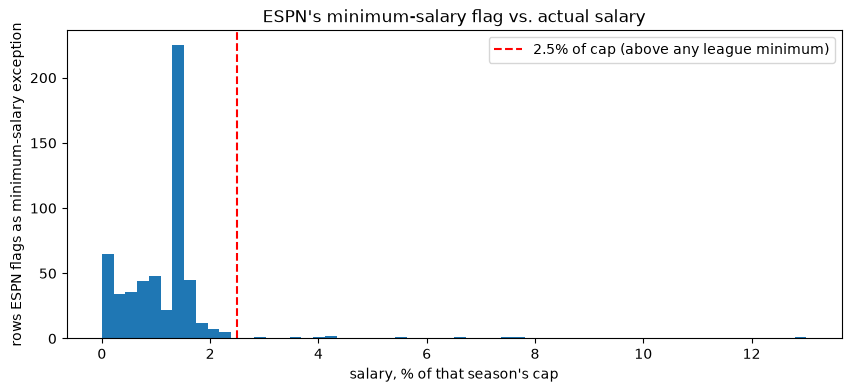

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(flagged['salary_pct_of_cap'], bins=60)
ax.axvline(2.5, color='red', linestyle='--', label='2.5% of cap (above any league minimum)')
ax.set_xlabel('salary, % of that season\'s cap')
ax.set_ylabel('rows ESPN flags as minimum-salary exception')
ax.set_title('ESPN\'s minimum-salary flag vs. actual salary')
ax.legend()
plt.show()

**What we found:** Most flagged rows are at minimum-salary level, but some clearly aren't. Marvin Williams 2016-17 at \$12.25M and Luke Kennard 2024-25 at \$9.25M were not minimum deals. Most likely ESPN attaches the flag to the wrong contract year.

The highest minimum salary in any season (the 10+ year veteran minimum) is about **1.6%-2.4% of the cap**. So we keep ESPN's flag **only when the salary is at most 2.5% of that season's cap**:

`min_salary_contract = minimumSalaryException AND salary ≤ 2.5% of cap`

This matches what we know about the rules: a player the team could only sign *because* the minimum exception lets over-the-cap teams sign minimum players. To also require that the team is over the cap, combine it at the final merge with `over_cap` from notebook 02: `min_salary_contract & over_cap`.

## 5. Clean the data

In [18]:
clean = c.rename(columns={'yearsRemaining': 'years_remaining', 'minimumSalaryException': 'minimum_salary_exception',
                          'name': 'player_name', 'athlete_id': 'espn_athlete_id', 'salary': 'espn_salary'}).copy()

# 1. Shifted fields: yearsRemaining holds dollars, salaryRemaining holds the year count
swapped = clean['years_remaining'] > 10
clean.loc[swapped, 'years_remaining'] = clean.loc[swapped, 'salaryRemaining']
print('fixed swapped rows:', swapped.sum())

# 2. Impossible zeros -> missing
zeros = clean['years_remaining'] == 0
clean.loc[zeros, 'years_remaining'] = np.nan
clean['years_remaining'] = clean['years_remaining'].astype('Int64')
print('set years_remaining = 0 to missing:', zeros.sum())

# 3. Features
clean['expiring_contract'] = (clean['years_remaining'] == 1)                     # <NA> when years_remaining is missing
clean['min_salary_contract'] = clean['minimum_salary_exception'] & (clean['salary_pct_of_cap'] <= 2.5)

# 4. Team = end-of-season team from the stats leaderboard, in NBA abbreviations
clean['team'] = clean['team_abbrev_stats'].replace(ESPN_TO_NBA_ABBREV)
clean['name_key'] = clean['player_name'].map(normalize_name)

contract_features = (clean[['season', 'team', 'espn_athlete_id', 'player_name', 'name_key', 'espn_salary',
                            'years_remaining', 'expiring_contract', 'min_salary_contract']]
                     .query('@FIRST_SEASON <= season <= @LAST_SEASON')
                     .sort_values(['season', 'team', 'espn_salary'], ascending=[True, True, False])
                     .reset_index(drop=True))
contract_features.head()

fixed swapped rows: 2
set years_remaining = 0 to missing: 103


,season,team,espn_athlete_id,player_name,name_key,espn_salary,years_remaining,expiring_contract,min_salary_contract
0,2016,ATL,3015,Paul Millsap,paul millsap,18671659.0,3,False,False
1,2016,ATL,3213,Al Horford,al horford,12000000.0,1,True,False
2,2016,ATL,3233,Tiago Splitter,tiago splitter,9756250.0,2,False,False
3,2016,ATL,4015,Jeff Teague,jeff teague,8000000.0,2,False,False
4,2016,ATL,2011,Kyle Korver,kyle korver,5746479.0,2,False,False


In [19]:
print('teams:', sorted(contract_features['team'].unique()))
assert contract_features['team'].nunique() == 30
assert not contract_features.duplicated(['season', 'espn_athlete_id']).any()

dupe_names = contract_features[contract_features.duplicated(['season', 'name_key'], keep=False)]
print('season + name_key collisions (two different players with the same name):', len(dupe_names))
dupe_names[['season', 'team', 'player_name', 'espn_athlete_id']]

teams: ['ATL', 'BKN', 'BOS', 'CHA', 'CHI', 'CLE', 'DAL', 'DEN', 'DET', 'GSW', 'HOU', 'IND', 'LAC', 'LAL', 'MEM', 'MIA', 'MIL', 'MIN', 'NOP', 'NYK', 'OKC', 'ORL', 'PHI', 'PHX', 'POR', 'SAC', 'SAS', 'TOR', 'UTA', 'WAS']
season + name_key collisions (two different players with the same name): 0


,season,team,player_name,espn_athlete_id


In [20]:
pd.DataFrame({
    'players': contract_features.groupby('season').size(),
    'expiring %': contract_features.groupby('season')['expiring_contract'].mean().astype(float).mul(100).round(1),
    'min-salary %': contract_features.groupby('season')['min_salary_contract'].mean().mul(100).round(1),
    'median years left': contract_features.groupby('season')['years_remaining'].median(),
    'years_remaining missing': contract_features.groupby('season')['years_remaining'].apply(lambda s: s.isna().sum()),
})

,players,expiring %,min-salary %,median years left,years_remaining missing
season,,,,,
2016,467,31.2,18.0,2.0,9
2017,481,28.3,18.1,2.0,11
2018,457,40.0,14.9,2.0,5
2019,505,42.9,11.9,2.0,30
2020,449,32.3,10.9,2.0,19
2021,511,38.0,7.6,2.0,14
2022,508,34.2,10.6,2.0,5
2023,525,36.2,4.0,2.0,0
2024,541,37.8,7.4,2.0,6


**What we found:**

- **About a third of players are in the last year of their contract in any season**, which is plausible given how many NBA deals are 1-2 years. The median player has 2 years left.
- **The minimum-salary share falls over time** (about 18% of players in 2015-16, about 3-5% by 2024-26). We think that's because more fringe roster spots went to two-way contracts after 2017-18, but we haven't checked that.
- **No two ESPN players share a normalized name within a season**, so `season + name_key` is unique here. We still recommend joining on **`season + team + name_key`**, which also protects against same-name collisions in the other datasets.

## 6. Save

In [21]:
out = PROCESSED / 'espn_contract_features.csv'
contract_features.to_csv(out, index=False)
print('saved', contract_features.shape, 'to', out)

saved (5534, 9) to ..\..\data-files\02-processed\espn_contract_features.csv


**Output:** `data-files/02-processed/espn_contract_features.csv`, **one row per player + season** (team = end-of-season team).

| Column | Meaning |
|---|---|
| `season`, `team`, `name_key` | join keys (end year, NBA abbreviation, normalized name) |
| `espn_athlete_id`, `player_name` | identification |
| `espn_salary` | ESPN's salary figure, kept only to sanity-check the join against notebook 02 |
| `years_remaining` | years left on the contract, including this season (missing where ESPN's value was impossible) |
| `expiring_contract` | `True` if this is the contract's final season |
| `min_salary_contract` | `True` if signed with the minimum-salary exception at minimum-level pay |

**Notes for the final merge:** join to notebook 02 on `season + team + name_key`. In our checks, ~99.5% of ESPN rows matched a llimllib row on `season + name_key`. A player traded mid-season has one ESPN row, under his final team.